In [1]:
from pathlib import Path

# Locate CSV files inside the data folder
data_files = list(Path("../data").glob("*.csv"))

# Display the files found
for file in data_files:
    print(file)

../data/Telco-Customer-Churn - Clean_data.csv


In [2]:
import pandas as pd

# Load the cleaned customer churn dataset
df = pd.read_csv("../data/Telco-Customer-Churn - Clean_data.csv")

# Display the first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Tenure_group,Monthly_Charge_Group,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,Yes,Electronic check,29.85,29.85,No,0-12 months,Under $30,NaN,blank values for total charges,11.0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,Mailed check,56.95,1889.50,No,25-48 months,$30–$59.99,NaN,tenure for blank values for total charges,11.0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,Yes,Mailed check,53.85,108.15,Yes,0-12 months,$30–$59.99,NaN,Unique ID's,7043.0
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,Bank transfer (automatic),42.30,1840.75,No,25-48 months,$30–$59.99,NaN,NaN,NaN
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,Yes,Electronic check,70.70,151.65,Yes,0-12 months,$60–$89.99,NaN,NaN,NaN


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (7043, 26)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Tenure_group', 'Monthly_Charge_Group', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25']


In [4]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customerID            7043 non-null   str    
 1   gender                7043 non-null   str    
 2   SeniorCitizen         7043 non-null   int64  
 3   Partner               7043 non-null   str    
 4   Dependents            7043 non-null   str    
 5   tenure                7043 non-null   int64  
 6   PhoneService          7043 non-null   str    
 7   MultipleLines         7043 non-null   str    
 8   InternetService       7043 non-null   str    
 9   OnlineSecurity        7043 non-null   str    
 10  OnlineBackup          7043 non-null   str    
 11  DeviceProtection      7043 non-null   str    
 12  TechSupport           7043 non-null   str    
 13  StreamingTV           7043 non-null   str    
 14  StreamingMovies       7043 non-null   str    
 15  Contract   

In [5]:
df_analysis = df.loc[:, ~df.columns.str.startswith("Unnamed:")]

In [6]:
print("Analysis dataset shape:", df_analysis.shape)

print("\nMissing values by column:")
print(df_analysis.isnull().sum())

Analysis dataset shape: (7043, 23)

Missing values by column:
customerID               0
gender                   0
SeniorCitizen            0
Partner                  0
Dependents               0
tenure                   0
PhoneService             0
MultipleLines            0
InternetService          0
OnlineSecurity           0
OnlineBackup             0
DeviceProtection         0
TechSupport              0
StreamingTV              0
StreamingMovies          0
Contract                 0
PaperlessBilling         0
PaymentMethod            0
MonthlyCharges           0
TotalCharges            11
Churn                    0
Tenure_group             0
Monthly_Charge_Group     0
dtype: int64


In [7]:
missing_total = df_analysis[df_analysis["TotalCharges"].isnull()]

print("Number of missing TotalCharges:", len(missing_total))
print("\nTenure values for these customers:")
print(missing_total["tenure"].value_counts())

print("\nCustomer records:")
display(missing_total[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Number of missing TotalCharges: 11

Tenure values for these customers:
tenure
0    11
Name: count, dtype: int64

Customer records:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [8]:
# Check for duplicate customer IDs
duplicate_count = df_analysis["customerID"].duplicated().sum()

print("Duplicate customer records:", duplicate_count)

Duplicate customer records: 0


In [9]:
# Check unique values in the Churn column
print(df_analysis["Churn"].value_counts())

print("\nUnique Churn values:")
print(df_analysis["Churn"].unique())

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Unique Churn values:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [10]:
# Summary statistics for numerical columns
df_analysis[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


In [11]:
# Inspect unique categories in selected categorical columns

categorical_columns = [
    "gender",
    "InternetService",
    "Contract",
    "PaymentMethod",
    "SeniorCitizen"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df_analysis[column].value_counts())


gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

PaymentMethod:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

SeniorCitizen:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


In [12]:
print(df_analysis["PaymentMethod"].value_counts())
print("\nUnique payment methods:")
print(df_analysis["PaymentMethod"].unique())

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

Unique payment methods:
<StringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str


In [13]:
# Calculate customer churn distribution

churn_counts = df_analysis["Churn"].value_counts()

churn_percentage = df_analysis["Churn"].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({
    "Customer_Count": churn_counts,
    "Percentage": churn_percentage.round(2)
})

display(churn_summary)

,Customer_Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


Matplotlib is building the font cache; this may take a moment.


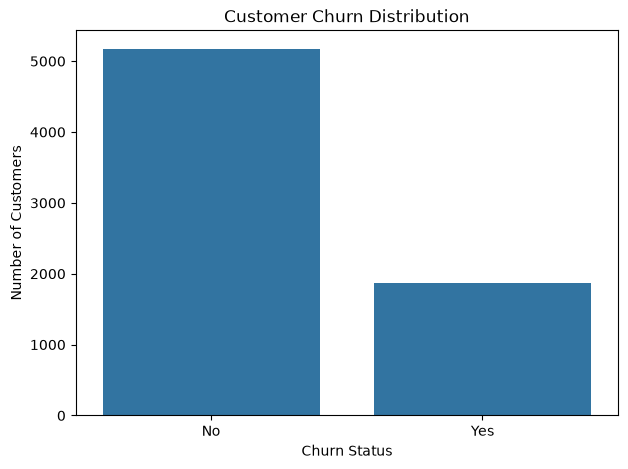

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.barplot(
    x=churn_summary.index,
    y=churn_summary["Customer_Count"]
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [15]:
contract_churn = pd.crosstab(
    df_analysis["Contract"],
    df_analysis["Churn"]
)

contract_churn["Total_Customers"] = contract_churn.sum(axis=1)

contract_churn["Churn_Rate"] = (
    contract_churn["Yes"] / contract_churn["Total_Customers"] * 100
).round(2)

display(contract_churn)

Churn,No,Yes,Total_Customers,Churn_Rate
Contract,,,,
Month-to-month,2220,1655,3875,42.71
One year,1307,166,1473,11.27
Two year,1647,48,1695,2.83


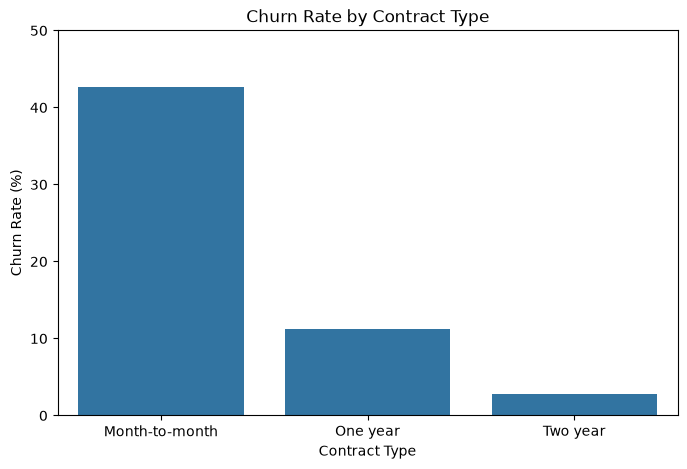

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_analysis,
    x="Contract",
    y=df_analysis["Churn"].map({"No": 0, "Yes": 1}) * 100,
    errorbar=None
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

plt.show()

In [17]:
tenure_churn = pd.crosstab(
    df_analysis["Tenure_group"],
    df_analysis["Churn"]
)

tenure_churn["Total_Customers"] = tenure_churn.sum(axis=1)

tenure_churn["Churn_Rate"] = (
    tenure_churn["Yes"] / tenure_churn["Total_Customers"] * 100
).round(2)

display(tenure_churn)

Churn,No,Yes,Total_Customers,Churn_Rate
Tenure_group,,,,
0-12 months,1149,1037,2186,47.44
13-24 months,730,294,1024,28.71
25-48 months,1269,325,1594,20.39
49+ months,2026,213,2239,9.51


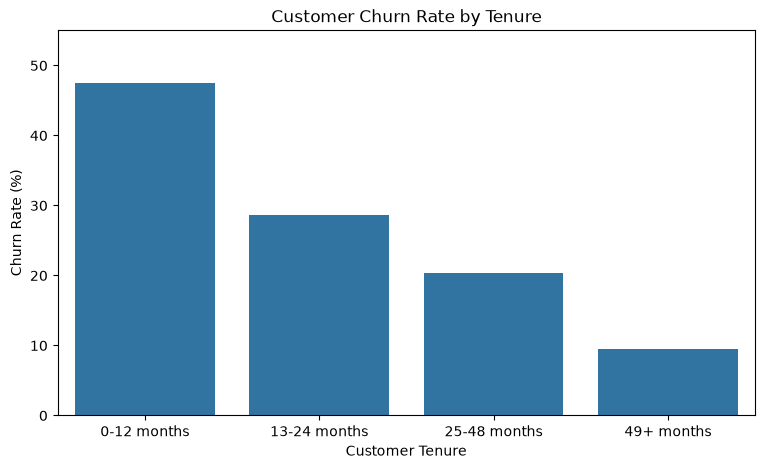

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_analysis,
    x="Tenure_group",
    y=df_analysis["Churn"].map({"No": 0, "Yes": 1}) * 100,
    errorbar=None,
    order=["0-12 months", "13-24 months", "25-48 months", "49+ months"]
)

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 55)

plt.show()

In [19]:
monthly_charges_churn = pd.crosstab(
    df_analysis["Monthly_Charge_Group"],
    df_analysis["Churn"]
)

monthly_charges_churn["Total_Customers"] = (
    monthly_charges_churn.sum(axis=1)
)

monthly_charges_churn["Churn_Rate"] = (
    monthly_charges_churn["Yes"]
    / monthly_charges_churn["Total_Customers"] * 100
).round(2)

display(monthly_charges_churn)

Churn,No,Yes,Total_Customers,Churn_Rate
Monthly_Charge_Group,,,,
$30–$59.99,927,327,1254,26.08
$60–$89.99,1585,807,2392,33.74
$90+,1171,573,1744,32.86
Under $30,1491,162,1653,9.80


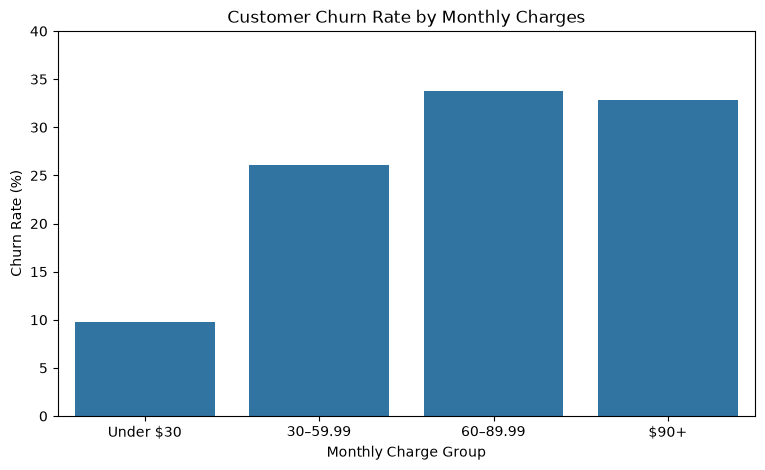

In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_analysis,
    x="Monthly_Charge_Group",
    y=df_analysis["Churn"].map({"No": 0, "Yes": 1}) * 100,
    errorbar=None,
    order=["Under $30", "$30–$59.99", "$60–$89.99", "$90+"]
)

plt.title("Customer Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 40)

plt.show()

In [21]:
payment_churn = pd.crosstab(
    df_analysis["PaymentMethod"],
    df_analysis["Churn"]
)

payment_churn["Total_Customers"] = payment_churn.sum(axis=1)

payment_churn["Churn_Rate"] = (
    payment_churn["Yes"]
    / payment_churn["Total_Customers"] * 100
).round(2)

display(payment_churn)

Churn,No,Yes,Total_Customers,Churn_Rate
PaymentMethod,,,,
Bank transfer (automatic),1286,258,1544,16.71
Credit card (automatic),1290,232,1522,15.24
Electronic check,1294,1071,2365,45.29
Mailed check,1304,308,1612,19.11


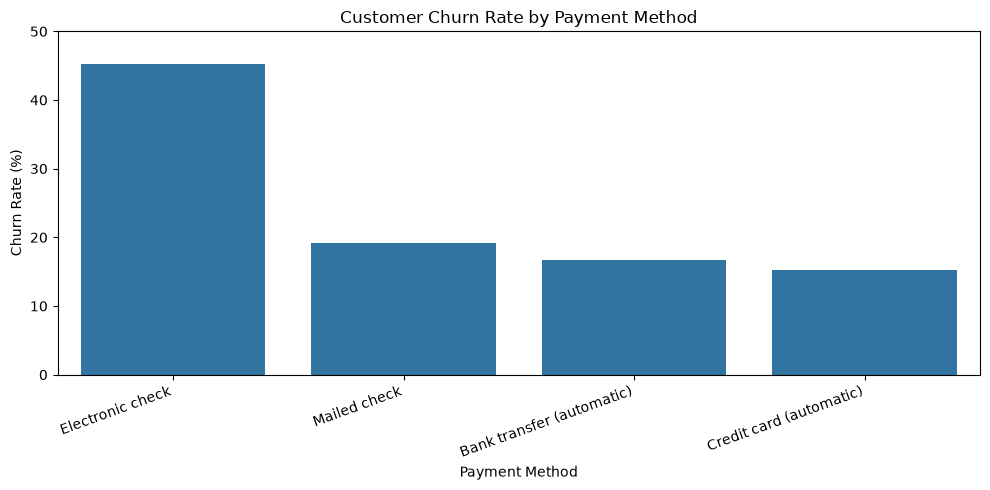

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_analysis,
    x="PaymentMethod",
    y=df_analysis["Churn"].map({"No": 0, "Yes": 1}) * 100,
    errorbar=None,
    order=[
        "Electronic check",
        "Mailed check",
        "Bank transfer (automatic)",
        "Credit card (automatic)"
    ]
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

In [23]:
internet_churn = pd.crosstab(
    df_analysis["InternetService"],
    df_analysis["Churn"]
)

internet_churn["Total_Customers"] = internet_churn.sum(axis=1)

internet_churn["Churn_Rate"] = (
    internet_churn["Yes"]
    / internet_churn["Total_Customers"] * 100
).round(2)

display(internet_churn)

Churn,No,Yes,Total_Customers,Churn_Rate
InternetService,,,,
DSL,1962,459,2421,18.96
Fiber optic,1799,1297,3096,41.89
No,1413,113,1526,7.40


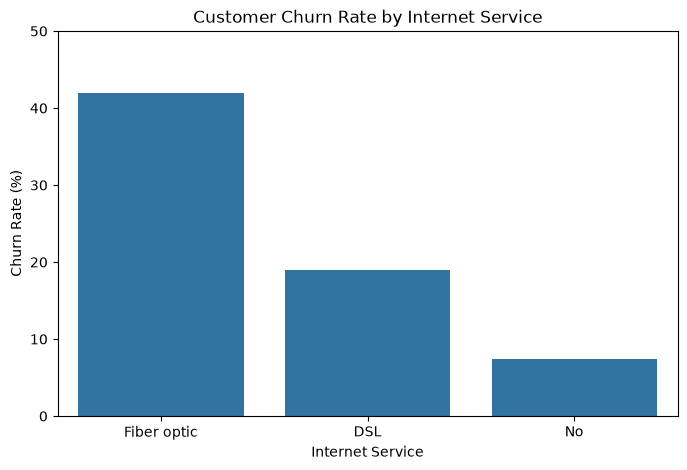

In [24]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_analysis,
    x="InternetService",
    y=df_analysis["Churn"].map({"No": 0, "Yes": 1}) * 100,
    errorbar=None,
    order=["Fiber optic", "DSL", "No"]
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

plt.show()

In [25]:
contract_tenure_churn = pd.crosstab(
    [df_analysis["Contract"], df_analysis["Tenure_group"]],
    df_analysis["Churn"]
)

contract_tenure_churn["Total_Customers"] = (
    contract_tenure_churn.sum(axis=1)
)

contract_tenure_churn["Churn_Rate"] = (
    contract_tenure_churn["Yes"]
    / contract_tenure_churn["Total_Customers"] * 100
).round(2)

display(contract_tenure_churn)

Churn                          No   Yes  Total_Customers  Churn_Rate
Contract       Tenure_group                                         
Month-to-month 0-12 months    970  1024             1994       51.35
               13-24 months   459   278              737       37.72
               25-48 months   538   264              802       32.92
               49+ months     253    89              342       26.02
One year       0-12 months    111    13              124       10.48
               13-24 months   181    16              197        8.12
               25-48 months   463    55              518       10.62
               49+ months     552    82              634       12.93
Two year       0-12 months     68     0               68        0.00
               13-24 months    90     0               90        0.00
               25-48 months   268     6              274        2.19
               49+ months    1221    42             1263        3.33

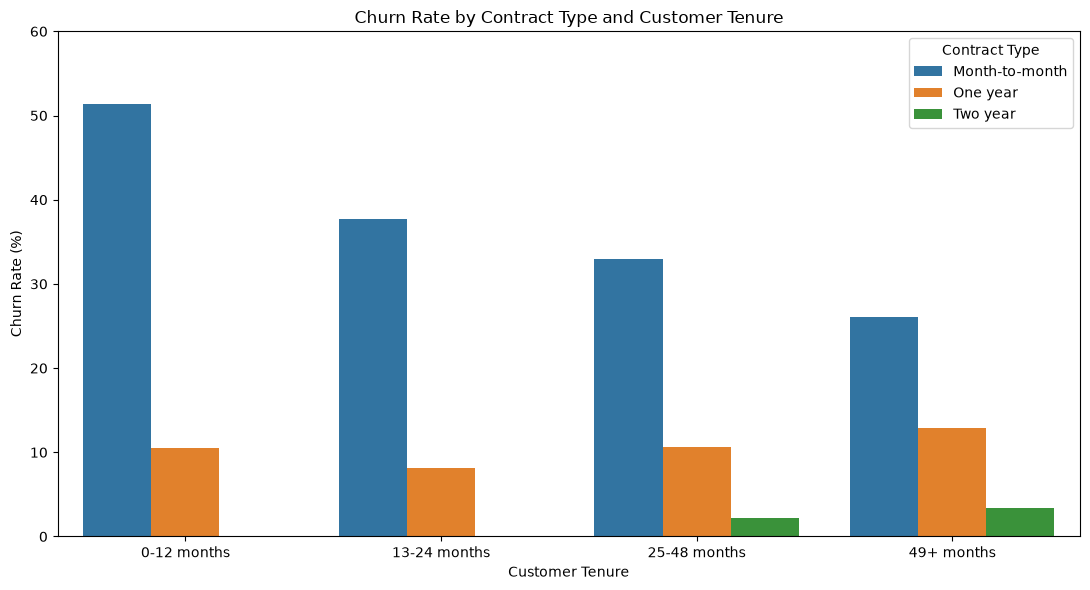

In [26]:
contract_tenure_plot = contract_tenure_churn.reset_index()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=contract_tenure_plot,
    x="Tenure_group",
    y="Churn_Rate",
    hue="Contract",
    order=["0-12 months", "13-24 months", "25-48 months", "49+ months"]
)

plt.title("Churn Rate by Contract Type and Customer Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 60)
plt.legend(title="Contract Type")

plt.tight_layout()
plt.show()

In [27]:
numerical_summary = df_analysis.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean().round(2)

display(numerical_summary)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2555.34
Yes,17.98,74.44,1531.80


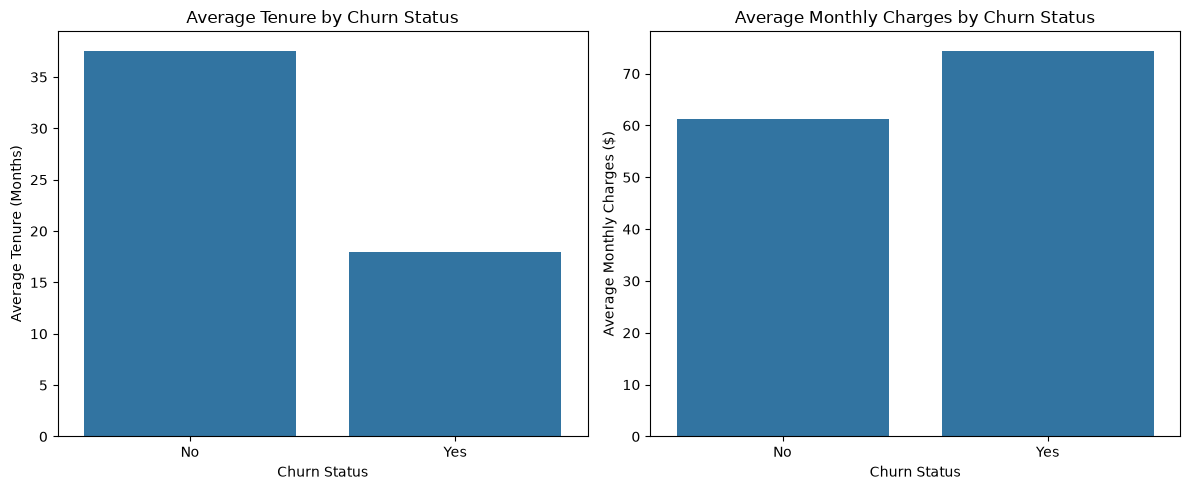

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=df_analysis,
    x="Churn",
    y="tenure",
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title("Average Tenure by Churn Status")
axes[0].set_xlabel("Churn Status")
axes[0].set_ylabel("Average Tenure (Months)")

sns.barplot(
    data=df_analysis,
    x="Churn",
    y="MonthlyCharges",
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Average Monthly Charges by Churn Status")
axes[1].set_xlabel("Churn Status")
axes[1].set_ylabel("Average Monthly Charges ($)")

plt.tight_layout()
plt.show()

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


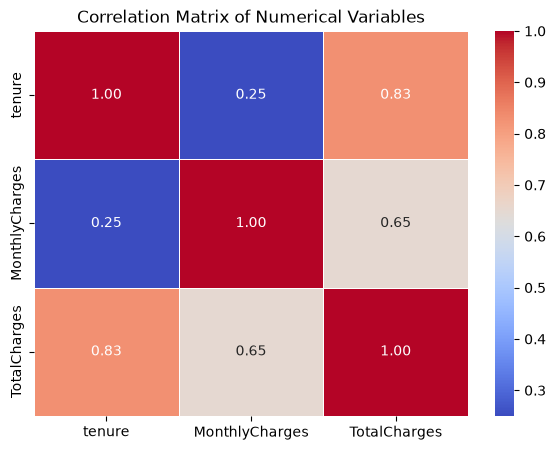

In [29]:
correlation_matrix = df_analysis[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr().round(2)

display(correlation_matrix)

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

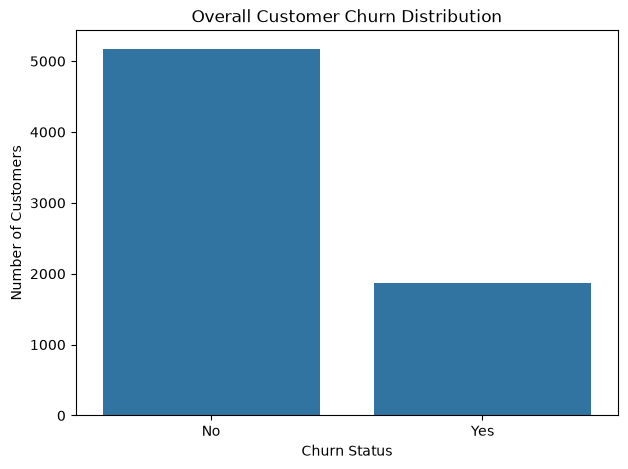

In [31]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=churn_summary.index,
    y=churn_summary["Customer_Count"]
)

plt.title("Overall Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.savefig(
    "../visualisation/01_overall_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

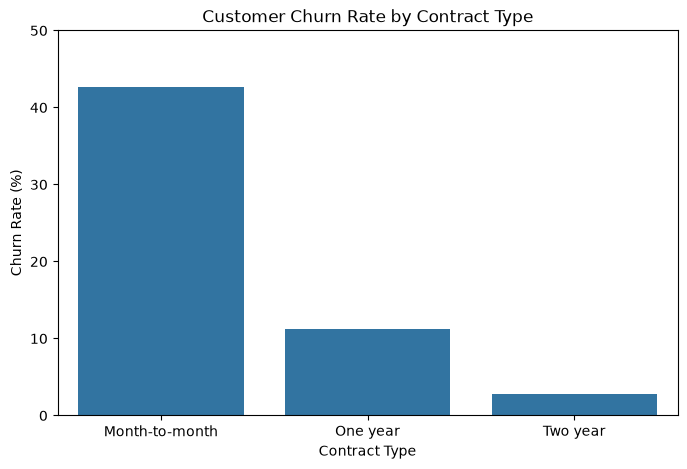

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn["Churn_Rate"]
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

plt.savefig(
    "../visualisation/02_churn_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

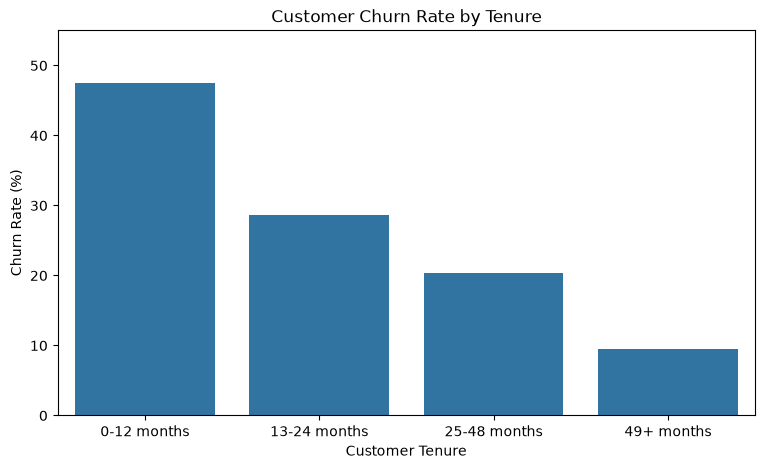

In [33]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_analysis,
    x="Tenure_group",
    y=df_analysis["Churn"].map({"No": 0, "Yes": 1}) * 100,
    errorbar=None,
    order=["0-12 months", "13-24 months", "25-48 months", "49+ months"]
)

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 55)

plt.savefig(
    "../visualisation/03_churn_by_tenure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

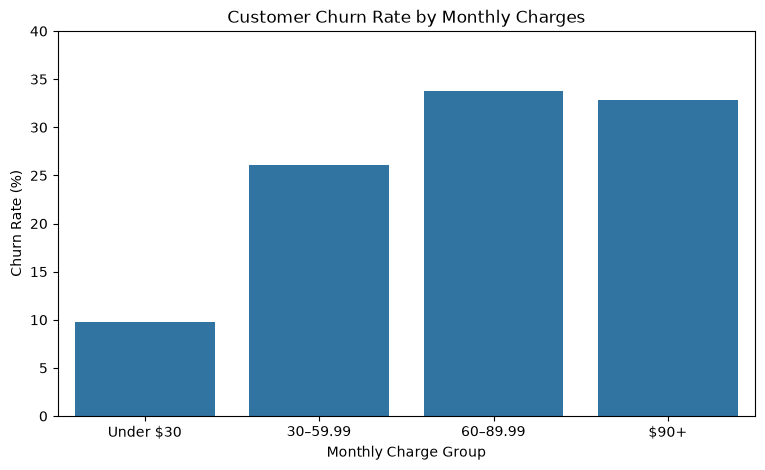

In [34]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_analysis,
    x="Monthly_Charge_Group",
    y=df_analysis["Churn"].map({"No": 0, "Yes": 1}) * 100,
    errorbar=None,
    order=["Under $30", "$30–$59.99", "$60–$89.99", "$90+"]
)

plt.title("Customer Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 40)

plt.savefig(
    "../visualisation/04_churn_by_monthly_charges.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

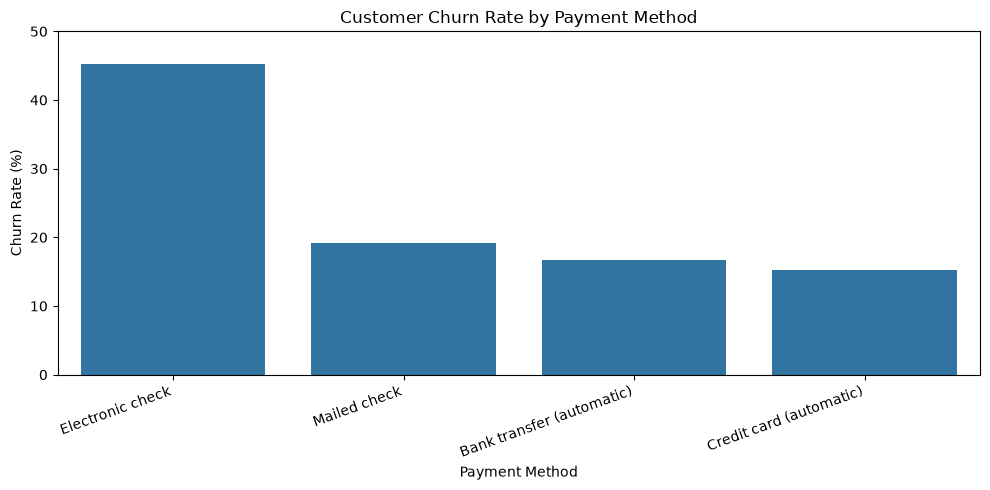

In [35]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_churn.index,
    y=payment_churn["Churn_Rate"],
    order=[
        "Electronic check",
        "Mailed check",
        "Bank transfer (automatic)",
        "Credit card (automatic)"
    ]
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.xticks(rotation=20, ha="right")

plt.tight_layout()

plt.savefig(
    "../visualisation/05_churn_by_payment_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

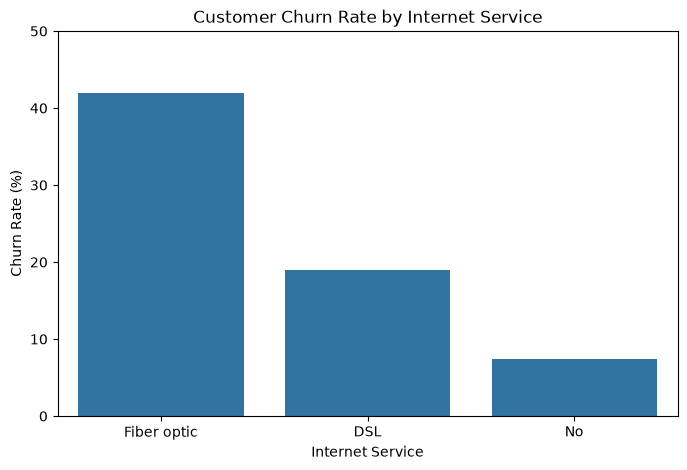

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn["Churn_Rate"],
    order=["Fiber optic", "DSL", "No"]
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

plt.savefig(
    "../visualisation/06_churn_by_internet_service.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

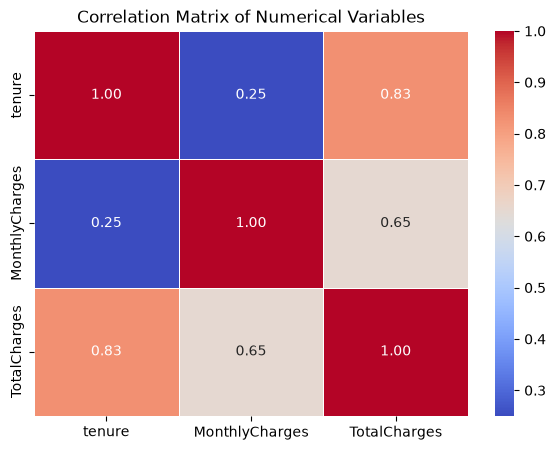

In [37]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Variables")

plt.savefig(
    "../visualisation/07_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
# Export the analysis-ready dataset for Power BI

df_analysis.to_csv(
    "../data/customer_churn_powerbi.csv",
    index=False
)

print("Power BI dataset exported successfully!")
print("Dataset shape:", df_analysis.shape)

Power BI dataset exported successfully!
Dataset shape: (7043, 23)
